# 任务三 D/E：树模型与全不流失基线

角色 C：邓闽川。复用角色 A 的 `prepare_data()`：`random_state=42`、80/20 分层划分。三组模型都在同一个留出测试集上按 `1=流失` 评分。

In [1]:
from IPython.display import Image, display

from tasks_de import OUTPUT_DIR, run_experiment

models, metrics, depth_scan, feature_importance = run_experiment()
dt = models['决策树']
rf = models['随机森林']
metric_labels = {'model': '模型', 'acc': '准确率', 'sens': '灵敏度', 'spec': '特异度', 'auc': 'AUC'}

## E：全预测不流失

基线准确率等于测试集不流失客户的比例，不能证明模型能识别流失。因为没有任何客户被判为流失，真正流失的客户全部漏掉；所有流失分数相同，ROC AUC 为 0.5。

In [2]:
print(metrics.loc[metrics['model'].eq('全不流失基线'), list(metric_labels)].rename(columns=metric_labels).to_string(index=False, float_format='{:.4f}'.format))

    模型    准确率    灵敏度    特异度    AUC
全不流失基线 0.7357 0.0000 1.0000 0.5000


## D：深度扫描与随机森林

扫描最大深度 2–15，以外层训练集内分层五折的平均验证 AUC 选深度。与模板直接看测试 AUC 不同，这里不让留出测试集参与选参；选定后用整个训练集重训。两种树模型都使用 A 的未缩放特征。

,max_depth,train_auc_mean,validation_auc_mean,validation_auc_std,selected
3,5,0.8544,0.8159,0.0107,True


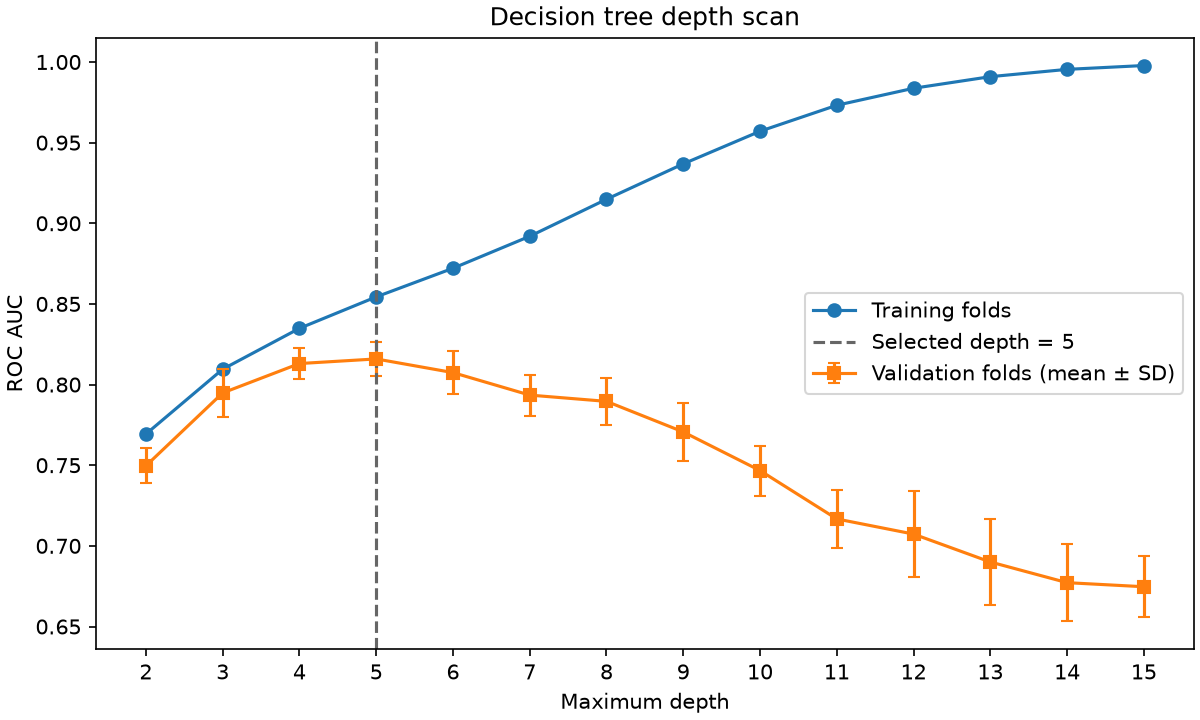

  模型    准确率    灵敏度    特异度    AUC
 决策树 0.7872 0.4937 0.8927 0.8141
随机森林 0.8071 0.5377 0.9040 0.8284


In [3]:
display(depth_scan.loc[depth_scan['selected']].round(4))
display(Image(filename=OUTPUT_DIR / 'fig05_tree_depth.png'))
print(metrics.loc[metrics['model'].isin(['决策树', '随机森林']), list(metric_labels)].rename(columns=metric_labels).to_string(index=False, float_format='{:.4f}'.format))

随机森林用自助抽样和随机特征子集降低不同树的相关性，再对多棵树的概率取平均，通常能降低相对于单棵树的预测方差。下图展示训练所得的杂质下降重要性，只反映模型对特征的使用，不证明因果关系。

与 A 的 EDA 部分一致：`tenure` 和 `MonthlyCharges` 都在前 3，A 也比较了它们在流失和不流失组中的分布。`TotalCharges` 排第一，但它和在网时长、月费相关，不能把重要性直接当作独立影响。

feature
TotalCharges      0.1939
MonthlyCharges    0.1696
tenure            0.1622
Name: importance, dtype: float64

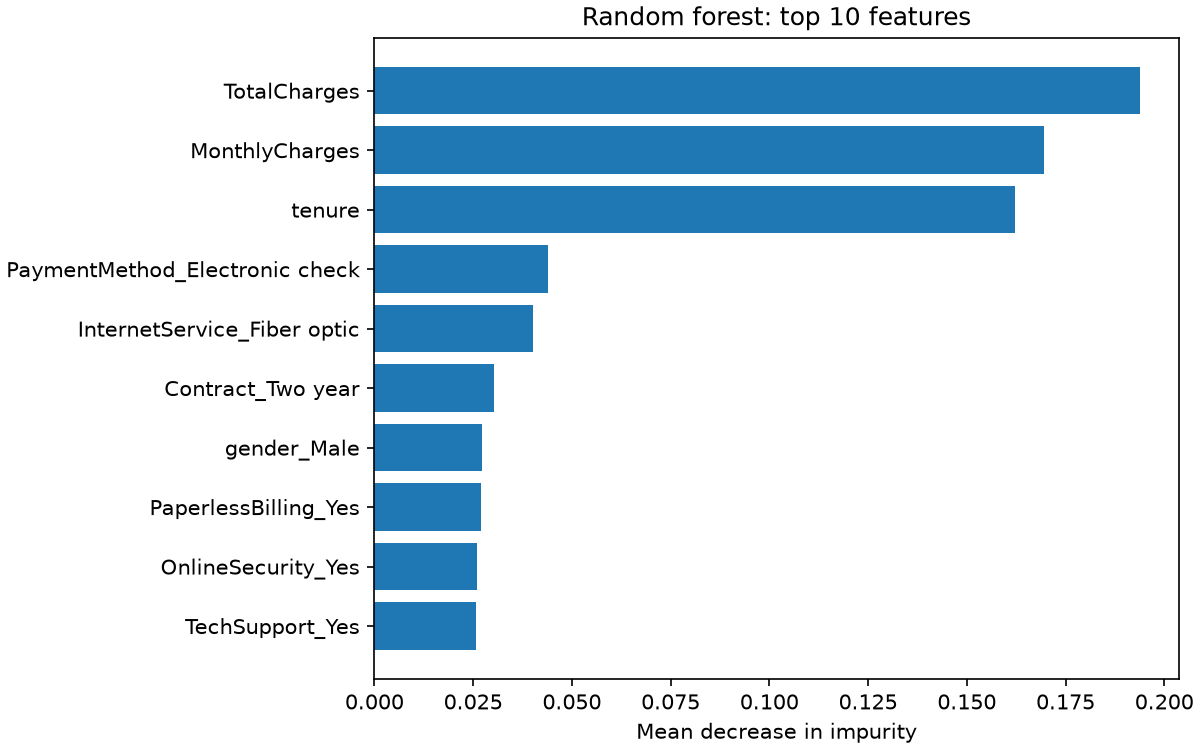

In [4]:
display(feature_importance.head(3).round(4))
display(Image(filename=OUTPUT_DIR / 'fig06_rf_importance.png'))